## 1. Carga de datos

Se conecta a la base SQLite `olist.db` y se trae el universo de pedidos con estado `delivered`, incluyendo datos como fecha de compra, fecha de entrega estimada y fecha de entrega real.

In [1]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

conn = sqlite3.connect('../data/processed/olist.db')

def query(sql):
    return pd.read_sql_query(sql, conn)

columnas_fechas = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

query("SELECT name FROM sqlite_master WHERE type='table';")

,name
0,customers
1,geolocation
2,orders
3,order_items
4,order_payments
5,order_reviews
6,products
7,sellers


In [2]:
df_entregas = query("""
    SELECT 
        order_id,
        order_status,
        order_purchase_timestamp,
        order_delivered_customer_date,
        order_estimated_delivery_date
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL;
""")

## 2. Cálculo de retraso y días de entrega

Se convierten las fechas a `datetime` y se calculan dos variables derivadas:
- `dias_entrega_real`: días transcurridos entre la compra y la entrega real.
- `pedido_con_retraso`: booleano, retorna `True` si la entrega real ocurrió después de la fecha estimada.

In [3]:
for col in columnas_fechas:
    df_entregas[col] = pd.to_datetime(df_entregas[col])

df_entregas['dias_entrega_real'] = (
    df_entregas['order_delivered_customer_date'] - df_entregas['order_purchase_timestamp']
).dt.total_seconds() / 86400.0

df_entregas['pedido_con_retraso'] = (
    df_entregas['order_delivered_customer_date'] > df_entregas['order_estimated_delivery_date']
)

In [4]:
df_entregas['pedido_con_retraso'].value_counts(normalize = True) * 100

pedido_con_retraso
False    91.887633
True      8.112367
Name: proportion, dtype: float64

## 3. Tasa de retraso por estado

Se trae el mismo universo de pedidos, esta vez con el `customer_state`, para calcular la tasa de retraso por estado y poder compararlos entre sí.

In [5]:
df_retrasos_estado = query("""
SELECT
    o.order_id,
    c.customer_state,
    o.order_purchase_timestamp,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
WHERE o.order_status = 'delivered'
    AND o.order_delivered_customer_date IS NOT NULL;
""")

for col in columnas_fechas:
    df_retrasos_estado[col] = pd.to_datetime(df_retrasos_estado[col])

df_retrasos_estado['pedido_con_retraso'] = (
    df_retrasos_estado['order_delivered_customer_date'] > df_retrasos_estado['order_estimated_delivery_date']
)

## 4. Caso de estudio: Maranhao (MA)

Maranhao es uno de los estados con mayor tasa de retraso. Se trae la calificación de los pedidos junto con las fechas de entrega, para evaluar si el retraso tiene un efecto medible sobre la satisfacción del cliente en ese estado en particular.

In [6]:
satisfaccion_ma = query("""
SELECT
    r.review_score,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    c.customer_state
FROM order_reviews r
JOIN orders o ON o.order_id = r.order_id
JOIN customers c ON c.customer_id = o.customer_id
WHERE o.order_status = 'delivered'
    AND c.customer_state = 'MA'
""")

In [7]:
satisfaccion_ma['order_delivered_customer_date'] = pd.to_datetime(satisfaccion_ma['order_delivered_customer_date'])
satisfaccion_ma['order_estimated_delivery_date'] = pd.to_datetime(satisfaccion_ma['order_estimated_delivery_date'])

satisfaccion_ma['pedido_con_retraso'] = (
    satisfaccion_ma['order_delivered_customer_date'] > satisfaccion_ma['order_estimated_delivery_date']
)

satisfaccion_ma[satisfaccion_ma['pedido_con_retraso']]

,review_score,order_delivered_customer_date,order_estimated_delivery_date,customer_state,pedido_con_retraso
4,2,2018-01-04 20:26:46,2017-12-19,MA,True
13,3,2018-01-06 17:07:34,2018-01-05,MA,True
14,2,2017-12-01 21:21:12,2017-11-30,MA,True
15,4,2017-10-08 15:40:04,2017-10-04,MA,True
16,1,2018-08-05 11:42:39,2018-08-01,MA,True
...,...,...,...,...,...
677,1,2017-12-18 22:10:09,2017-12-14,MA,True
681,3,2018-05-04 10:52:23,2018-05-04,MA,True
683,1,2018-01-05 11:19:40,2017-12-27,MA,True
701,4,2018-04-30 16:48:50,2018-04-04,MA,True


In [8]:
satisfaccion_ma[satisfaccion_ma['pedido_con_retraso']]['review_score'].value_counts(normalize=True) * 100

review_score
1    49.635036
5    18.248175
3    11.678832
4    11.678832
2     8.759124
Name: proportion, dtype: float64

In [9]:
satisfaccion_ma.groupby('pedido_con_retraso')['review_score'].mean().round(2)

pedido_con_retraso
False    4.18
True     2.40
Name: review_score, dtype: float64

## 5. Tabla de hechos y dimensiones para Power BI

Se arma un modelo de datos tipo estrella para exportar a CSV e importarlos en Power BI.

In [11]:
df_fact = query("""
    SELECT 
        o.order_id,
        o.customer_id,
        oi.product_id,
        oi.seller_id,
        o.order_purchase_timestamp,
        o.order_delivered_customer_date,
        o.order_estimated_delivery_date,
        oi.price,
        oi.freight_value,
        r.review_score
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN order_reviews r ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL;
""")

In [12]:
for col in columnas_fechas:
    df_fact[col] = pd.to_datetime(df_fact[col])

df_fact = df_fact.drop_duplicates(subset=['order_id', 'product_id', 'seller_id', 'price', 'freight_value'])

df_fact['dias_entrega_real'] = (
    (df_fact['order_delivered_customer_date'] - df_fact['order_purchase_timestamp']).dt.total_seconds() / 86400.0
).round(2)

df_fact['retraso'] = (
    df_fact['order_delivered_customer_date'] > df_fact['order_estimated_delivery_date']
).astype(int)

df_fact['flete_mayor_precio'] = (
    df_fact['freight_value'] > df_fact['price']
).astype(int)

In [13]:
dim_customers = query("""
    SELECT DISTINCT 
        customer_id,
        customer_unique_id,
        customer_city,
        customer_state
    FROM customers;
""")

dim_products = query("""
    SELECT DISTINCT 
        product_id,
        product_category_name
    FROM products;
""")

dim_sellers = query("""
    SELECT DISTINCT 
        seller_id,
        seller_city,
        seller_state
    FROM sellers;
""")

In [ ]:
df_fact.to_csv('fact_pedidos.csv', index=False)
dim_customers.to_csv('dim_customers.csv', index=False)
dim_products.to_csv('dim_products.csv', index=False)
dim_sellers.to_csv('dim_sellers.csv', index=False)

print("Exportación completa:")
print(f"- fact_pedidos: {len(df_fact)} filas")
print(f"- dim_customers: {len(dim_customers)} filas")
print(f"- dim_products: {len(dim_products)} filas")
print(f"- dim_sellers: {len(dim_sellers)} filas")

## 6. Modelo: ¿el retraso afecta la calificación a nivel nacional?

Se repite el cálculo de retraso y calificación, ahora para todos los estados, y se ajusta una regresión lineal para cuantificar el efecto a nivel país, no solo en MA.

In [14]:
satisfaccion_pais = query("""
SELECT
    o.order_id,
    r.review_score,
    o.order_delivered_customer_date,
    o.order_estimated_delivery_date,
    c.customer_state
FROM order_reviews r
JOIN orders o ON o.order_id = r.order_id
JOIN customers c ON c.customer_id = o.customer_id
WHERE o.order_status = 'delivered'
    AND o.order_delivered_customer_date IS NOT NULL
""")

satisfaccion_pais = satisfaccion_pais.drop_duplicates(subset='order_id')

satisfaccion_pais['order_delivered_customer_date'] = pd.to_datetime(satisfaccion_pais['order_delivered_customer_date'])
satisfaccion_pais['order_estimated_delivery_date'] = pd.to_datetime(satisfaccion_pais['order_estimated_delivery_date'])
satisfaccion_pais['pedido_con_retraso'] = (
    satisfaccion_pais['order_delivered_customer_date'] > satisfaccion_pais['order_estimated_delivery_date']
).astype(int)

modelo = smf.ols('review_score ~ pedido_con_retraso', data=satisfaccion_pais).fit()
print(modelo.summary())
print("R²:", modelo.rsquared)

                            OLS Regression Results                            
Dep. Variable:           review_score   R-squared:                       0.133
Model:                            OLS   Adj. R-squared:                  0.133
Method:                 Least Squares   F-statistic:                 1.469e+04
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        20:08:14   Log-Likelihood:            -1.5324e+05
No. Observations:               95824   AIC:                         3.065e+05
Df Residuals:                   95822   BIC:                         3.065e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              4.2924      0

## 7. Margen de días vs. tasa de retraso por estado

Se calcula el margen (días estimados - días reales) a nivel de pedido y se agrega por estado, para evaluar si estados con menor margen tienen mayor tasa de retraso.

In [15]:
df_retrasos_estado['dias_estimados'] = (
    df_retrasos_estado['order_estimated_delivery_date'] - df_retrasos_estado['order_purchase_timestamp']
).dt.total_seconds() / 86400.0

df_retrasos_estado['dias_reales'] = (
    df_retrasos_estado['order_delivered_customer_date'] - df_retrasos_estado['order_purchase_timestamp']
).dt.total_seconds() / 86400.0

df_retrasos_estado['margen'] = df_retrasos_estado['dias_estimados'] - df_retrasos_estado['dias_reales']

agregado_estado = df_retrasos_estado.groupby('customer_state').agg(
    tasa_retraso=('pedido_con_retraso', 'mean'),
    margen_promedio=('margen', 'mean')
).reset_index()

agregado_estado['tasa_retraso'] = agregado_estado['tasa_retraso'] * 100

modelo_margen = smf.ols('tasa_retraso ~ margen_promedio', data=agregado_estado).fit()
print(modelo_margen.summary())
print("R²:", modelo_margen.rsquared)

                            OLS Regression Results                            
Dep. Variable:           tasa_retraso   R-squared:                       0.512
Model:                            OLS   Adj. R-squared:                  0.492
Method:                 Least Squares   F-statistic:                     26.18
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           2.76e-05
Time:                        20:08:14   Log-Likelihood:                -72.110
No. Observations:                  27   AIC:                             148.2
Df Residuals:                      25   BIC:                             150.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          24.2359      2.785     

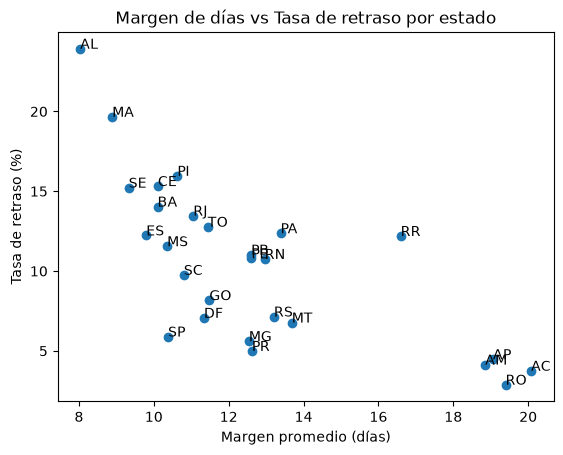

In [16]:
plt.scatter(agregado_estado['margen_promedio'], agregado_estado['tasa_retraso'])
plt.xlabel('Margen promedio (días)')
plt.ylabel('Tasa de retraso (%)')
plt.title('Margen de días vs Tasa de retraso por estado')
for _, row in agregado_estado.iterrows():
    plt.annotate(row['customer_state'], (row['margen_promedio'], row['tasa_retraso']))
plt.show()

## 8. ¿Cómo varía la calificación según los días exactos de retraso?

En vez de tratar el retraso como 0/1, se calcula `dias_retraso` como variable continua, para ver si el impacto en la calificación es gradual o si ocurre un salto abrupto al cruzar de \"a tiempo\" a \"con retraso\".

In [17]:
satisfaccion_pais['dias_retraso'] = (
    satisfaccion_pais['order_delivered_customer_date'] - satisfaccion_pais['order_estimated_delivery_date']
).dt.total_seconds() / 86400.0

Text(0.5, 1.0, 'Calificación promedio según días de retraso')

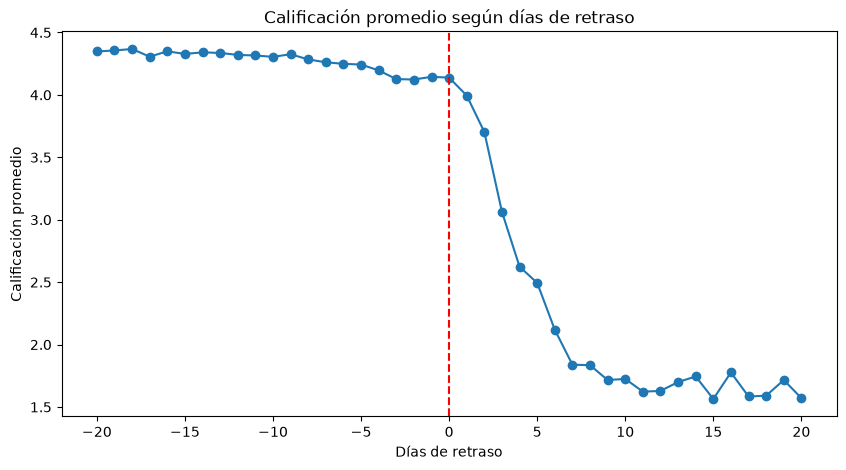

In [18]:
df_bin = satisfaccion_pais[(satisfaccion_pais['dias_retraso'] >= -20) & (satisfaccion_pais['dias_retraso'] <= 20)].copy()
df_bin['dias_retraso_int'] = df_bin['dias_retraso'].round().astype(int)

promedio_por_dia = df_bin.groupby('dias_retraso_int')['review_score'].mean()

plt.figure(figsize=(10,5))
plt.plot(promedio_por_dia.index, promedio_por_dia.values, marker='o')
plt.axvline(0, color='red', linestyle='--')
plt.xlabel('Días de retraso')
plt.ylabel('Calificación promedio')
plt.title('Calificación promedio según días de retraso')

## 9. Nordeste vs. Nacional: ¿se sostiene el patrón en la región con más retrasos?

El top 6 de estados con mayor tasa de retraso corresponden al Nordeste, con los márgenes de entrega más ajustados del país. Se compara la curva de calificación de Nordeste contra el promedio nacional para confirmar la presencia del mismo patrón de impacto por retraso. 

Text(0.5, 1.0, 'Calificación promedio según días de retraso: Nordeste vs. Nacional')

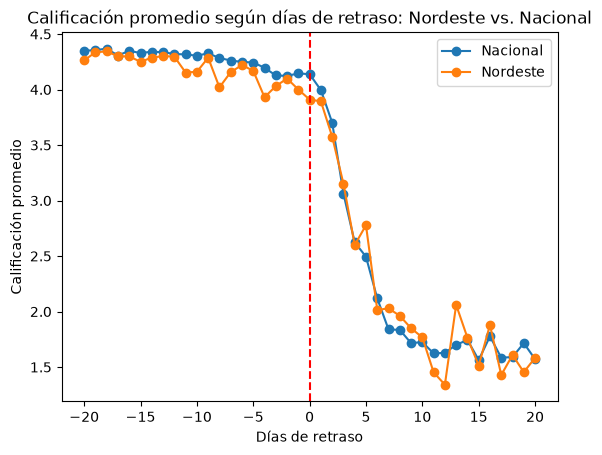

In [19]:
nordeste = ['AL', 'MA', 'PI', 'CE', 'SE', 'BA', 'RN', 'PB', 'PE']
df_nordeste = satisfaccion_pais[satisfaccion_pais['customer_state'].isin(nordeste)]

for nombre, data in [('Nacional', satisfaccion_pais), ('Nordeste', df_nordeste)]:
    data_filtrada = data[(data['dias_retraso'] >= -20) & (data['dias_retraso'] <= 20)].copy()
    data_filtrada['dias_retraso_int'] = data_filtrada['dias_retraso'].round().astype(int)
    promedio = data_filtrada.groupby('dias_retraso_int')['review_score'].mean()
    plt.plot(promedio.index, promedio.values, marker='o', label=nombre)

plt.axvline(0, color='red', linestyle='--')
plt.xlabel('Días de retraso')
plt.ylabel('Calificación promedio')
plt.legend()
plt.title('Calificación promedio según días de retraso: Nordeste vs. Nacional')